# 02 Peak Hours

## From 01

- 27 series: NO₂ 15 stations, PM2.5 12 (mc027, mc145, mc282 NO₂ only)
- Coverage 98.5–99.9%
- Hour = hour start (shifted −1h)
- `fireworks` flag: 31 Dec 18:00 – 1 Jan 06:00
- Max NO₂ 121, max PM2.5 276 µg/m³
- Top 10 PM2.5 hours all New Year, 6 stations in the same hour
- Top 10 NO₂ hours all March, 18:00–21:00, mostly traffic
- Values are integers

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Cleaned table from 01. Drops and fireworks flag already applied.
# CSV stores the offset as text, so parse to UTC then convert, as in 01.
ROOT = Path.cwd().parent
df = pd.read_csv(ROOT / "data" / "processed" / "hourly.csv")
df["datetime"] = pd.to_datetime(df["datetime"], utc=True).dt.tz_convert("Europe/Berlin")

# Full names for figures. pm2 is the API's code for PM2.5.
LABEL = {
    "no2": "NO₂ · traffic exhaust · airways",
    "pm2": "PM2.5 · mostly carried in · heart and blood vessels",
}

print(df.shape)
print(df["core"].value_counts())

(236180, 7)
core
no2    131288
pm2    104892
Name: count, dtype: int64


In [10]:
# Average by hour of day: every 07:00 of the year becomes one number.
# Averages, not single peaks. Is 07:00 reliably bad?
# mean() skips nulls.
mat = (
    df.groupby(["core", "station", df["datetime"].dt.hour])["value"]
    .mean()
    .rename("mean")
    .reset_index()
    .rename(columns={"datetime": "hour"})      # the hour key inherits the source column name
)

mat.head()

,core,station,hour,mean
0,no2,mc010,0,19.435616
1,no2,mc010,1,17.585165
2,no2,mc010,2,16.200549
3,no2,mc010,3,15.882192
4,no2,mc010,4,16.463014


In [11]:
# 15 NO₂ × 24 h = 360, 12 PM2.5 × 24 = 288. Each station should show 24.
# size() counts nulls too, so totals run above the valid hours in 01.
print(mat.groupby("core").size())
print(mat.groupby(["core", "station"]).size().value_counts())

core
no2    360
pm2    288
dtype: int64
24    27
Name: count, dtype: int64


In [12]:
# Top 10 % of station-hours. Cutoff = 90th percentile within each pollutant.
# Separate cutoffs because PM2.5 sits lower. One shared cutoff would select only NO₂.
# H1: do the top cells cluster at a few stations?
for core, g in mat.groupby("core"):
    cut = g["mean"].quantile(0.90)             # the threshold
    top = g[g["mean"] >= cut]                  # cells at or above it
    print(
        core,
        "| cutoff", round(cut, 1),             # µg/m³
        "| cells", len(top), "of", len(g),     # ~36 of 360, ~29 of 288
        "| stations", top["station"].nunique(),  # few = H1 holds
        "| hours", top["hour"].nunique(),
    )

no2 | cutoff 27.4 | cells 36 of 360 | stations 5 | hours 12
pm2 | cutoff 14.2 | cells 29 of 288 | stations 4 | hours 12


In [13]:
# Which stations hold those cells, and the annual means behind them.
# A top decile always has members. The spread shows whether it matters.
for core, g in mat.groupby("core"):
    cut = g["mean"].quantile(0.90)
    print(core, g[g["mean"] >= cut]["station"].value_counts().to_dict())

# Station annual means, best to worst
print(df.groupby(["core", "station"])["value"].mean().round(1))

no2 {'mc124': 11, 'mc144': 10, 'mc190': 7, 'mc221': 5, 'mc174': 3}
pm2 {'mc124': 9, 'mc174': 8, 'mc144': 7, 'mc221': 5}
core  station
no2   mc010      18.0
      mc027       8.4
      mc032       7.8
      mc042      15.2
      mc077       9.2
      mc085       7.8
      mc117      16.2
      mc124      26.3
      mc144      25.7
      mc145       7.6
      mc171      15.2
      mc174      23.7
      mc190      24.4
      mc221      22.4
      mc282      12.8
pm2   mc010      10.9
      mc032       8.2
      mc042      12.0
      mc077       9.2
      mc085       9.4
      mc117      11.0
      mc124      13.6
      mc144      13.4
      mc171      11.7
      mc174      13.6
      mc190      12.5
      mc221      13.1
Name: value, dtype: float64


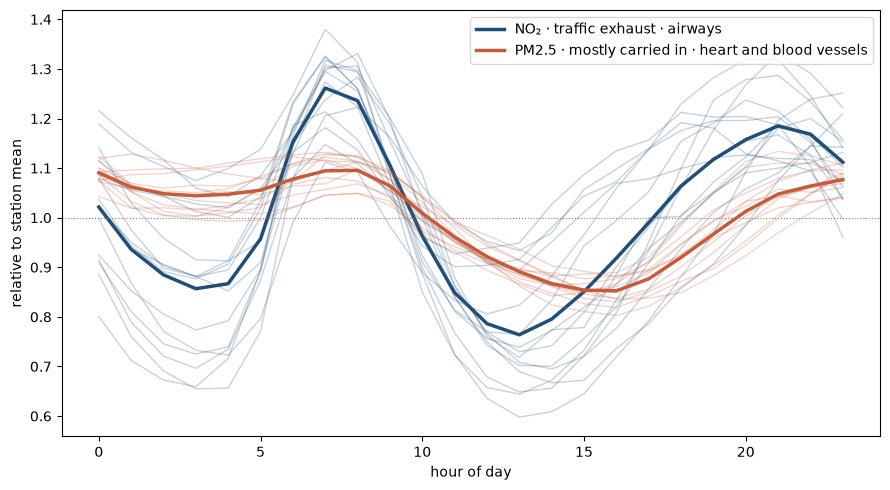

In [14]:
# Each station-hour as a share of that station's own yearly mean.
# 1.0 = typical for that station. Removes the level difference so the
# daily shape of the two pollutants can be compared directly.
rel = mat.copy()
rel["rel"] = rel["mean"] / rel.groupby(["core", "station"])["mean"].transform("mean")

fig, ax = plt.subplots(figsize=(9, 5))

for core, colour in [("no2", "#1f4e79"), ("pm2", "#c75b39")]:
    g = rel[rel["core"] == core]
    for st, s in g.groupby("station"):
        ax.plot(s["hour"], s["rel"], color=colour, alpha=0.25, lw=1)
    ax.plot(g.groupby("hour")["rel"].mean(), color=colour, lw=2.5, label=LABEL[core])

ax.axhline(1, color="grey", lw=0.8, ls=":")
ax.set_xlabel("hour of day")
ax.set_ylabel("relative to station mean")
ax.legend()

plt.tight_layout()
plt.savefig(ROOT / "figures" / "02_daily_cycle_relative.png", dpi=150)

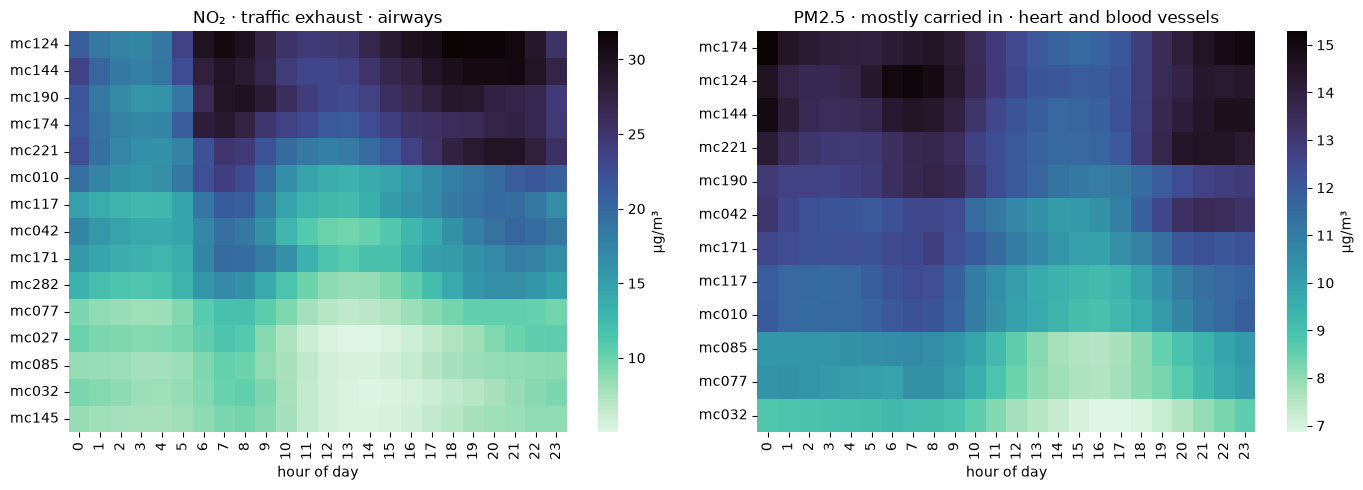

In [15]:
# Station × hour, one panel per pollutant. Rows sorted worst to best.
# Separate scales because levels differ. Single hue for colour vision deficiency.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, core in zip(axes, ["no2", "pm2"]):
    p = mat[mat["core"] == core].pivot(index="station", columns="hour", values="mean")
    p = p.loc[p.mean(axis=1).sort_values(ascending=False).index]
    sns.heatmap(p, ax=ax, cmap="mako_r", cbar_kws={"label": "µg/m³"})
    ax.set_title(LABEL[core])
    ax.set_xlabel("hour of day")
    ax.set_ylabel("")

plt.tight_layout()
(ROOT / "figures").mkdir(exist_ok=True)
plt.savefig(ROOT / "figures" / "02_heatmap.png", dpi=150)

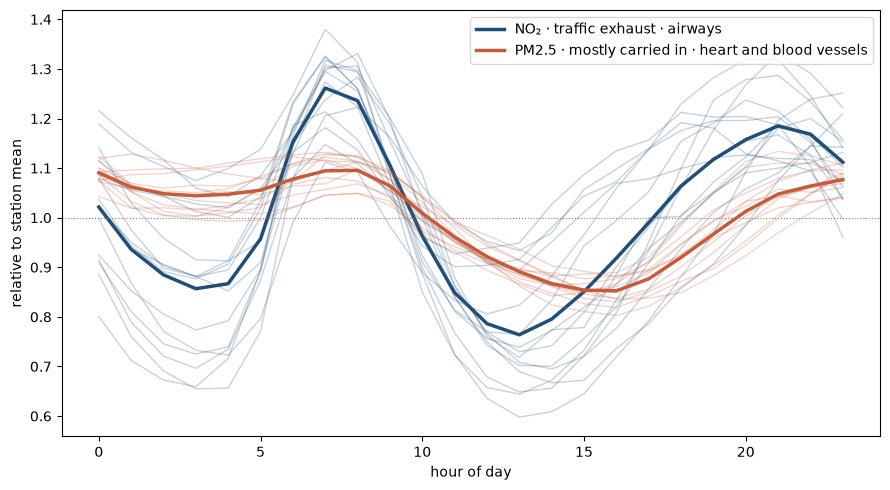

In [16]:
# Each station-hour as a share of that station's own yearly mean.
# 1.0 = typical for that station. Removes the level difference so the
# daily shape of the two pollutants can be compared directly.
rel = mat.copy()
rel["rel"] = rel["mean"] / rel.groupby(["core", "station"])["mean"].transform("mean")

fig, ax = plt.subplots(figsize=(9, 5))

for core, colour in [("no2", "#1f4e79"), ("pm2", "#c75b39")]:
    g = rel[rel["core"] == core]
    for st, s in g.groupby("station"):
        ax.plot(s["hour"], s["rel"], color=colour, alpha=0.25, lw=1, label="_nolegend_")
    ax.plot(g.groupby("hour")["rel"].mean(), color=colour, lw=2.5, label=LABEL[core])

ax.axhline(1, color="grey", lw=0.8, ls=":")
ax.set_xlabel("hour of day")
ax.set_ylabel("relative to station mean")
ax.legend()

plt.tight_layout()
plt.savefig(ROOT / "figures" / "02_daily_cycle_relative.png", dpi=150)